<center><h1>Initial Concentrations</h1></center>
<hr/>

Assigns an initial concentration to every PSS species by biological type:

| Type | Value | Source |
|---|---|---|
| **Protein / Protein active** | per-species median | PaxDb (`CONCENTRATIONS_A_THALIANA`) |
| **Protein / Protein active** (unmapped) | global median of mapped proteins | fallback |
| **Metabolite** | per-species value | metabolite file (`CONCENTRATIONS_METABOLITES`) |
| **Metabolite** (unmapped) | global median of mapped metabolites | fallback |
| **Gene** | `1e-5` | fixed low value |
| **mRNA / ncRNA / miRNA** | `4.9` | 2.6 / 6.1 / 4.9 → median chosen |
| Complex, Abiotic, Process, Process active | `protein_conc_global_median / 2` | placeholder |

> **TODO**: confirm units — all concentrations should be in mM before saving.

In [1]:
import math
import re
from pathlib import Path

import dill
import numpy as np
import pandas as pd

from typing import Optional

from scripts.utils import (
    INITIAL_CONCENTRATIONS,
    PSS_REACTIONS_PATH,
    PSS_SPECIES_PATH,
    PSS_INITIAL_CONCENTRATION_MAPPER,
    RED, RESET,
    plt, sns,
)

## Load

In [2]:
import json

reactions = json.loads(Path(PSS_REACTIONS_PATH).read_text())
species   = json.loads(Path(PSS_SPECIES_PATH).read_text())

print(f"Loaded {RED}{len(species)}{RESET} species and {RED}{len(reactions)}{RESET} reactions.")

Loaded 1139 species and 864 reactions.


In [3]:
concentrations = pd.read_csv(INITIAL_CONCENTRATIONS)

## Protein Concentrations

Map PSS protein names to PaxDb entries via A. thaliana homologue IDs (e.g. `AT1G01010`).

In [4]:
protein_concentrations = concentrations[concentrations['specie'] == 'protein'].copy()

# Strip isoform suffix from IDs (e.g. 'AT1G01010.1' → 'AT1G01010')
protein_concentrations['string_external_id'] = (
    protein_concentrations['string_external_id'].str.split('.').str[0]
)

protein_concentrations.head()

,compound,string_external_id,Estimated_conc_[nM],conc. [pM],conc. [mM],specie
66,NaN,ATCG00490,17231.031048,NaN,0.017231,protein
67,NaN,ATCG00680,5576.539930,NaN,0.005577,protein
68,NaN,AT2G39730,4824.838121,NaN,0.004825,protein
69,NaN,ATCG00270,4628.507388,NaN,0.004629,protein
70,NaN,ATCG00480,2849.493608,NaN,0.002849,protein


In [5]:
# Species whose type requires a protein concentration lookup
pss_proteins     = [s for s in species if species[s]['type'] in ('protein', 'protein_active')]
print(f"{RED}{len(pss_proteins)}{RESET} protein/protein_active species in PSS.")

603 protein/protein_active species in PSS.


In [6]:
def extract_ath_homologues(item: str) -> tuple[list[str], str]:
    """Parse 'Name[AT1G01010, AT2G12345]' into (homologue_ids, name).

    Args:
        item: A PSS protein name string, optionally containing ATH IDs in brackets.

    Returns:
        A tuple of (list of ATH gene IDs, base name before the bracket).
    """
    match = re.match(r'^([^\[]+)\[([^\]]+)\]', item.strip())
    if not match:
        return [], item

    name     = match.group(1)
    genes    = [g.strip() for g in match.group(2).split(',')]
    homologues = [g for g in genes if re.match(r'^AT[0-9A-Za-z.]+$', g)]
    return homologues, name

In [7]:
# Build per-protein concentration lists (multiple homologues → multiple values)
pax_ids = set(protein_concentrations['string_external_id'])

protein_conc: dict[str, list[float]] = {}
for specie_id in pss_proteins:
    name = species[specie_id]['name']
    for ath_id in extract_ath_homologues(name)[0]:
        if ath_id in pax_ids:
            conc_mM = protein_concentrations.loc[
                protein_concentrations['string_external_id'] == ath_id,
                'conc. [mM]'
            ].values[0]
            protein_conc.setdefault(name, []).append(conc_mM)

print(f"Mapped {RED}{len(protein_conc)}{RESET} / {RED}{len(pss_proteins)}{RESET} proteins from PSS.")

Mapped 369 / 603 proteins from PSS.


### Visualise protein concentration spread

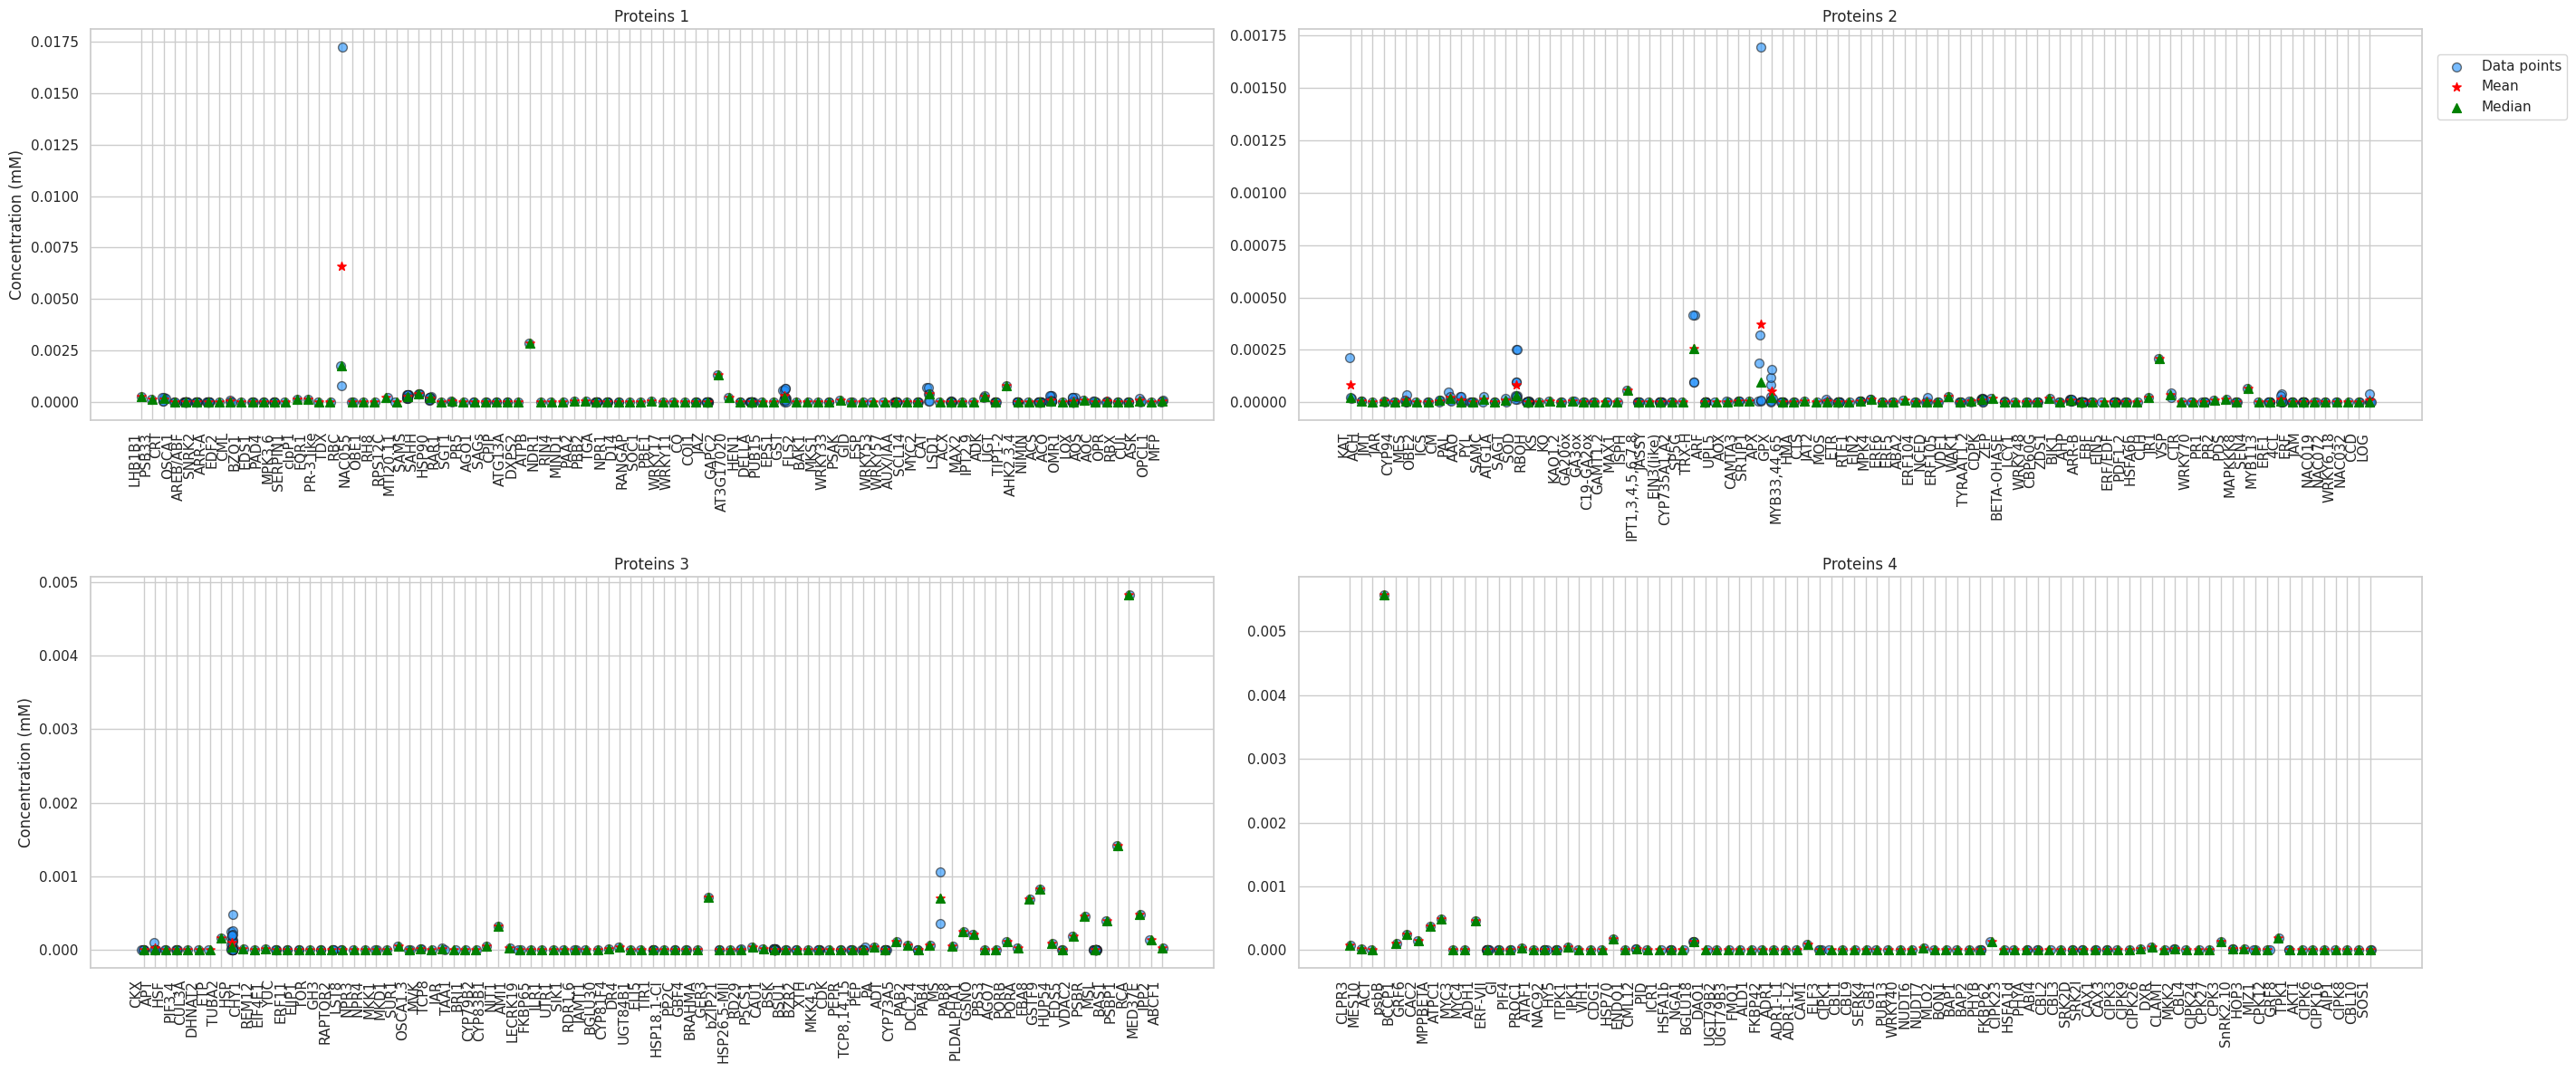

In [8]:
proteins      = list(protein_conc.keys())
species_names = {k: extract_ath_homologues(k)[1] for k in proteins}

num_subplots = 4
group_size   = math.ceil(len(proteins) / num_subplots)
groups       = [proteins[i*group_size:(i+1)*group_size] for i in range(num_subplots)]

fig, axes = plt.subplots(2, 2, figsize=(30, 12))
axes = axes.flatten()

for ax_idx, group in enumerate(groups):
    ax = axes[ax_idx]
    for i, prot in enumerate(group):
        values     = protein_conc[prot]
        x          = np.random.normal(i, 0.07, size=len(values))
        ax.scatter(x, values, color='dodgerblue', alpha=0.6, edgecolor='k', s=50,
                   label='Data points' if i == 0 else '')
        ax.scatter(i, np.mean(values),   color='red',   marker='*', s=50, label='Mean'   if i == 0 else '')
        ax.scatter(i, np.median(values), color='green', marker='^', s=50, label='Median' if i == 0 else '')
    ax.set_xticks(range(len(group)))
    ax.set_xticklabels([species_names[p] for p in group], rotation=90, ha='right')
    ax.set_title(f'Proteins {ax_idx + 1}')
    ax.set_ylabel('Concentration (mM)')
    ax.grid(True)

axes[1].set_ylabel('')
axes[3].set_ylabel('')

handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper right', bbox_to_anchor=(0.95, 0.95))
plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

In [9]:
protein_conc_global_median = np.median(sum(protein_conc.values(), []))
print(f"Global median initial concentration for {RED}protein{RESET} / {RED}protein_active{RESET}: {RED}{protein_conc_global_median:.4e}{RESET} mM.")

Global median initial concentration for protein / protein_active: 1.0667e-06 mM.


## Metabolite Concentrations

In [10]:
metabolite_concentrations = concentrations[concentrations['specie'] == 'metabolite']
metabolite_concentrations.head()

,compound,string_external_id,Estimated_conc_[nM],conc. [pM],conc. [mM],specie
0,ABA,NaN,NaN,10714.940299,1.071494e-05,metabolite
1,GA3,NaN,NaN,3295.278725,3.295279e-06,metabolite
2,JA,NaN,NaN,75.845779,7.584578e-08,metabolite
3,JAc2,NaN,NaN,75.845779,7.584578e-08,metabolite
4,OPDA,NaN,NaN,1.159135,1.159135e-09,metabolite


In [11]:
len([specie for specie in species if species[specie]['type'] == 'metabolite'])

160

In [12]:
pss_metabolites = {species[s]['name']: s for s in species if species[s]['type'] == 'metabolite'}

metabolite_conc = {
    compound: conc
    for compound, conc in (
        metabolite_concentrations[metabolite_concentrations['compound'].isin(pss_metabolites)]
        [['compound', 'conc. [mM]']]
        .values
    )
}
# Drop entries where parsing returned None
metabolite_conc = {m: c for m, c in metabolite_conc.items() if c is not None and c is not np.nan and pd.notna(c)}

print(f"Mapped {RED}{len(metabolite_conc)}{RESET} / {RED}{len([s for s in species if species[s]['type'] == 'metabolite'])}{RESET} metabolites from PSS.")

Mapped 7 / 160 metabolites from PSS.


In [13]:
metabolite_conc

{'ABA': 1.0714940299e-05,
 'JA': 7.584577855e-08,
 'OPDA': 1.1591348173e-09,
 'IAA': 2.07505034e-07,
 'SA': 7.3368061153e-07,
 'tZ': 1.865e-09,
 'cZ': 1.42e-09}

In [14]:
metabolite_conc_global_median = np.median(list(metabolite_conc.values()))
print(f"Global median initial concentration for {RED}metabolites{RESET}: {RED}{metabolite_conc_global_median:.4e}{RESET} mM.")

Global median initial concentration for metabolites: 7.5846e-08 mM.


## Build Concentration Mapper

In [15]:
def build_concentration_mapper(
    species:                        dict,
    protein_conc:                   dict,
    metabolite_conc:                dict,
    protein_conc_global_median:     float,
    metabolite_conc_global_median:  float,
) -> callable:
    """Build a self-contained initial-concentration callable and return it.

    All data is captured in the closure at build time so the returned
    callable can be serialised with dill and loaded independently.

    Args:
        species:                       Species dict keyed by ID.
        protein_conc:                  {name: [conc, ...]} for mapped proteins (mM).
        metabolite_conc:               {name: conc} for mapped metabolites (mM).
        protein_conc_global_median:    Fallback for unmapped proteins (mM).
        metabolite_conc_global_median: Fallback for unmapped metabolites (mM).

    Returns:
        initial_concentration(specie_id: str) → float
    """
    # Bake all data into plain local variables — no external references.
    _species_type  = {sid: info['type'] for sid, info in species.items()}
    _species_name  = {sid: info['name'] for sid, info in species.items()}
    _protein_conc  = {k: list(v) for k, v in protein_conc.items()}
    _met_conc      = dict(metabolite_conc)
    _prot_median   = protein_conc_global_median
    _met_median    = metabolite_conc_global_median

    def initial_concentration(specie: str) -> float:
        """Return the initial concentration (mM) for *specie*.

        Self-contained: all lookup data is baked into this closure.
        Safe to serialise with dill and load in a fresh Python session.
        """
        stype = _species_type[specie]
        name  = _species_name[specie]

        if stype in ('protein', 'protein_active'):
            return np.median(_protein_conc[name]) if name in _protein_conc else _prot_median
        if stype == 'metabolite':
            return _met_conc[name] if name in _met_conc else _met_median
        if stype == 'gene':
            return 1e-5
        if stype in ('mrna', 'ncrna', 'mirna'):
            return 4.9
        return _prot_median / 2   # complex, abiotic, process, process_active

    return initial_concentration

In [16]:
initial_concentration = build_concentration_mapper(
    species,
    protein_conc,
    metabolite_conc,
    protein_conc_global_median,
    metabolite_conc_global_median,
)

### Example usage

In [17]:
first_rxn_id   = next(iter(reactions))
first_rxn_info = reactions[first_rxn_id]
print(f"Reaction: {RED}{first_rxn_id}{RESET}")
print(first_rxn_info)

for entity in (s for vals in first_rxn_info.values() for s in vals):
    print(f"  {entity} → {RED}{initial_concentration(entity):.4e}{RESET} mM")

Reaction: rx00669
{'reactants': ['s_VPg_cyt_p', 's_LHB1B1_cyt_p'], 'products': ['s_LHB1B1VPg_cyt_c'], 'modifiers': []}
  s_VPg_cyt_p → 1.0667e-06 mM
  s_LHB1B1_cyt_p → 2.6606e-04 mM
  s_LHB1B1VPg_cyt_c → 5.3337e-07 mM


## Visualise Initial Concentrations

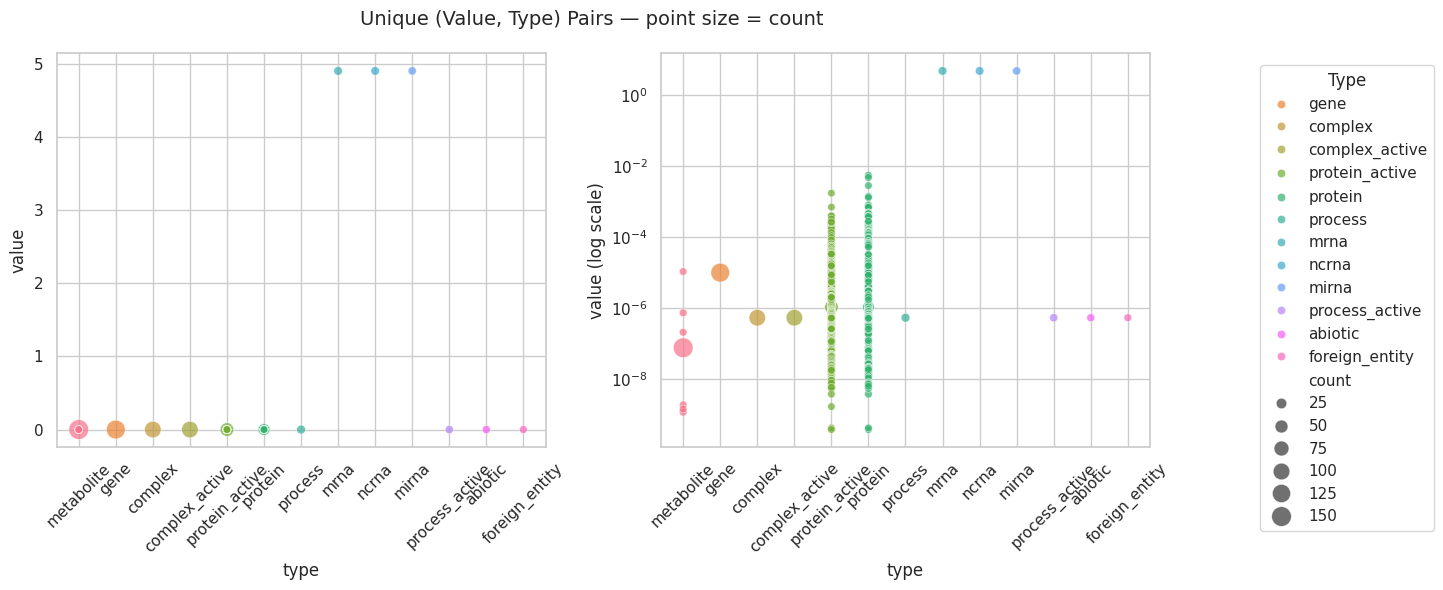

In [18]:
all_species = {s for r in reactions.values() for vals in r.values() for s in vals}

rows = [(s, initial_concentration(s), species[s]['type']) for s in all_species]
df   = pd.DataFrame(rows, columns=['specie', 'value', 'type'])

counts = df.value_counts(subset=['value', 'type']).reset_index(name='count')

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 6))

for ax in (ax_left, ax_right):
    sns.scatterplot(
        data=counts, x='type', y='value', size='count', hue='type',
        sizes=(30, 200), alpha=0.7, ax=ax,
    )
    ax.tick_params(axis='x', rotation=45)
    ax.get_legend().remove()

ax_right.set_yscale('log')
ax_right.set_ylabel('value (log scale)')

handles, labels_ = ax_left.get_legend_handles_labels()
fig.legend(handles[2:], labels_[2:], bbox_to_anchor=(1.05, 0.5), loc='center left', title='Type')

fig.suptitle('Unique (Value, Type) Pairs — point size = count', fontsize=14)
fig.tight_layout()
plt.show()

## Save

In [19]:
with open(PSS_INITIAL_CONCENTRATION_MAPPER, 'wb') as f:
    dill.dump(initial_concentration, f)

print(f"Saved concentration mapper → {PSS_INITIAL_CONCENTRATION_MAPPER}")

Saved concentration mapper → /home/ratanasoski/Desktop/Master_Thesis/ThesisRepository/results/concentration_mapper.pkl
